In [2]:
!curl -O https://raw.githubusercontent.com/karpathy/makemore/master/names.txt

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  222k  100  222k    0     0   389k      0 --:--:-- --:--:-- --:--:--  390k


In [3]:
words = open('names.txt', 'r').read().splitlines()

In [4]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [5]:
len(words)

32033

In [6]:
min(len(w) for w in words)

2

In [7]:
max(len(w) for w in words)

15

In [14]:
b = {}                                      # dictionary

for w in words:
    chs = ['<S>'] + list(w) + ['<E>']       # S is special start character and same for E
    for ch1, ch2 in zip(chs,chs[1:]):
        bigram = (ch1 ,ch2)
        b[bigram] = b.get(bigram, 0) + 1

In [15]:
sorted(b.items(), key = lambda kv : -kv[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [16]:
import torch

In [77]:
N = torch.zeros((27, 27), dtype = torch.int32)

In [78]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s  for s, i in stoi.items()}              # it's the reverse order of the stoi

In [79]:

for w in words:
    chs = ['.'] + list(w) + ['.']       # S is special start character and same for E
    for ch1, ch2 in zip(chs,chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] += 1

(np.float64(-0.5), np.float64(26.5), np.float64(26.5), np.float64(-0.5))

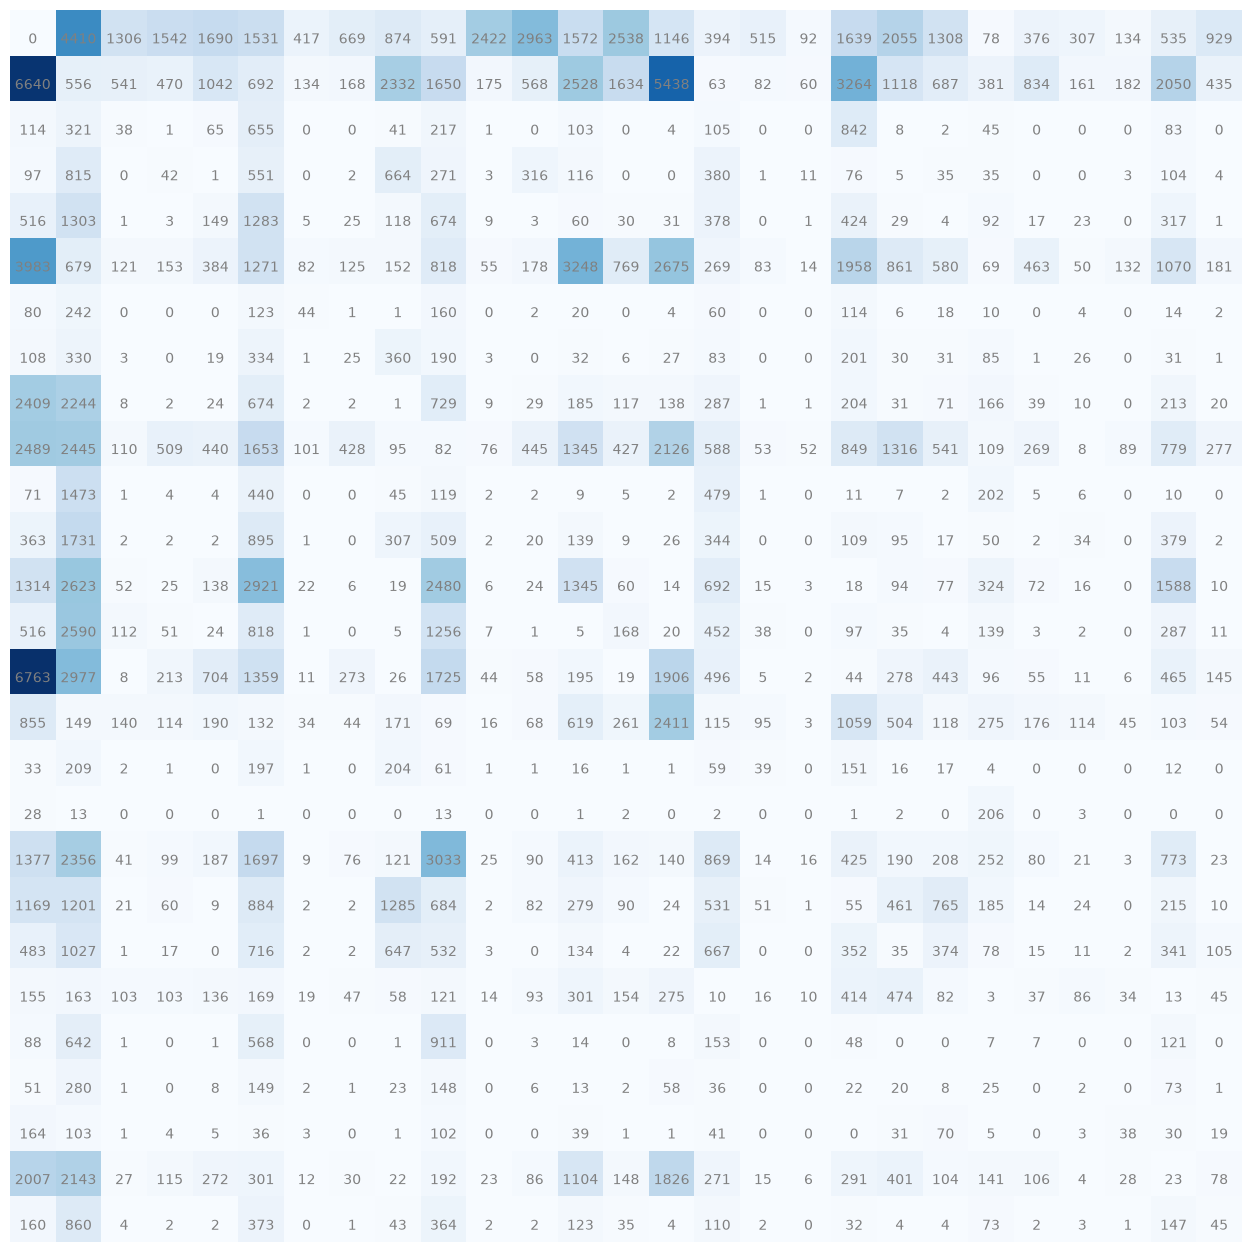

In [80]:
import matplotlib.pyplot as plt

%matplotlib inline

plt.figure(figsize=(16, 16))
plt.imshow(N, cmap="Blues")
for i in range(27):
  for j in range(27):
    chstr = itos[i] + itos[j]
    plt.text(j, i, N[i, j].item(), ha="center", va="top", color="grey")
plt.axis("off")

In [81]:
N[0]

tensor([   0, 4410, 1306, 1542, 1690, 1531,  417,  669,  874,  591, 2422, 2963,
        1572, 2538, 1146,  394,  515,   92, 1639, 2055, 1308,   78,  376,  307,
         134,  535,  929], dtype=torch.int32)

In [82]:
p = N[0].float()
p = p / p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [83]:
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples = 1, replacement = True, generator = g).item()
itos[ix]

'c'

In [84]:
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator = g)
p = p / p.sum()
p

tensor([0.6064, 0.3033, 0.0903])

In [85]:
torch.multinomial(p, num_samples = 100, replacement = True, generator = g)

tensor([1, 1, 2, 0, 0, 2, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 2, 0, 0,
        1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1,
        0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
        0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 1, 0, 0, 2, 0, 1, 0,
        0, 1, 1, 1])

In [86]:
P = N.float()

In [91]:
P.sum(1, keepdim = True).shape

torch.Size([27, 1])

In [203]:
P = (N+1).float()
P = P / P.sum(1, keepdim = True)

In [93]:
P[0].sum()

tensor(1.)

In [96]:
g = torch.Generator().manual_seed(2147483647)

for i in range(20):
    out = []
    ix = 0
    while True:
        # p = N[ix].float()
        # p = p / p.sum()

        p = P[ix]
        
        ix = torch.multinomial(p, num_samples = 1, replacement = True, generator = g).item()
        out.append(itos[ix])

        if ix == 0 :
            break
    print(''.join(out))

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.
ka.
emimmsade.
enkaviyny.
ftlspihinivenvorhlasu.
dsor.
br.
jol.
pen.
aisan.
ja.


In [ ]:
# GOAL: maximize likelihood of the data w.r.t. model parameters (statistical modeling)
# equivalent to maximizing the log likelihood (because log is monotonic)
# equivalent to minimizing the negative log likelihood
# equivalent to minimizing the average negative log likelihood

# log(a*b*c) = log(a) + log(b) + log(c)

In [120]:
log_likelihood = 0.0          # highest value can be 0
n = 0

for w in words:
# for w in ["andrejq"]:
# for w in ["a"]:
    chs = ['.'] + list(w) + ['.']
    for ch1 ,ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        prob = P[ix1, ix2]
        logprob = torch.log(prob)
        log_likelihood += logprob
        n += 1
        # print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(f'{log_likelihood = }')
nll = -log_likelihood
print(f'{nll = }')
print(f'{nll/n}')

log_likelihood = tensor(-559891.7500)
nll = tensor(559891.7500)
2.454094171524048


In [122]:
# create training sets of biagram

xs, ys = [], []

for w in words[:1]:
    chs = ['.'] + list(w) + ['.']
    for ch1 ,ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        print(ch1, ch2)
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)

. e
e m
m m
m a
a .


In [123]:
xs


tensor([ 0,  5, 13, 13,  1])

In [124]:
ys

tensor([ 5, 13, 13,  1,  0])

In [128]:
# one hot encoder 

import torch.nn.functional as F
xenc = F.one_hot(xs, num_classes = 27).float()
xenc

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

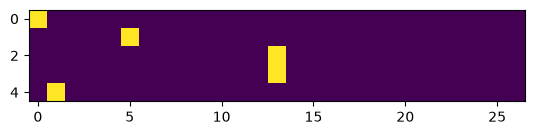

In [129]:
plt.imshow(xenc)

In [130]:
xenc.dtype

torch.float32

In [132]:
W = torch.randn((27,27))
xenc @ W                       # @ is the vector mul sign in pytorch


tensor([[-1.5163,  1.2558, -0.8602, -0.6944, -0.2741, -0.1237, -1.3028, -0.3668,
         -1.1684,  1.1772,  1.3090,  1.4236,  0.8798,  0.0140,  1.1154, -0.4365,
         -0.8110, -0.7944, -0.3855,  1.7451, -0.5959,  2.2123, -0.3762,  1.2734,
          0.2344, -1.4510, -1.3412],
        [ 0.3718,  0.2734, -2.4584,  1.4305, -0.3284, -0.1619,  0.4897, -0.5212,
         -0.3709,  0.7242,  0.1731,  0.1877,  2.2688, -1.0892, -1.4888, -2.0038,
          1.9446,  0.0440, -0.8413, -1.5255,  0.5705,  2.0463,  0.7018,  1.1485,
          1.0095,  1.0854, -2.1065],
        [-0.2399,  0.6723, -0.2108, -0.2561, -0.2893,  1.3333, -0.6570, -1.6564,
          0.8603,  2.7683, -0.1797, -0.3246,  1.0654, -1.8667, -1.0855, -0.3571,
         -1.2752,  0.1443, -1.7371, -0.7554, -0.2160,  0.5491, -0.1866,  0.7063,
          1.1952,  1.0942, -1.0761],
        [-0.2399,  0.6723, -0.2108, -0.2561, -0.2893,  1.3333, -0.6570, -1.6564,
          0.8603,  2.7683, -0.1797, -0.3246,  1.0654, -1.8667, -1.0855, -0.3571

In [136]:
# (xenc @ W).exp()   # same is below

logits = xenc @ W  # log-counts
counts = logits.exp()   # equivalent n
probs = counts / counts.sum(1, keepdims = True) 
probs

tensor([[0.0045, 0.0719, 0.0087, 0.0102, 0.0156, 0.0181, 0.0056, 0.0142, 0.0064,
         0.0665, 0.0759, 0.0851, 0.0494, 0.0208, 0.0625, 0.0132, 0.0091, 0.0093,
         0.0139, 0.1173, 0.0113, 0.1872, 0.0141, 0.0732, 0.0259, 0.0048, 0.0054],
        [0.0261, 0.0237, 0.0015, 0.0753, 0.0130, 0.0153, 0.0294, 0.0107, 0.0124,
         0.0372, 0.0214, 0.0217, 0.1741, 0.0061, 0.0041, 0.0024, 0.1259, 0.0188,
         0.0078, 0.0039, 0.0319, 0.1394, 0.0363, 0.0568, 0.0494, 0.0533, 0.0022],
        [0.0165, 0.0411, 0.0170, 0.0162, 0.0157, 0.0796, 0.0109, 0.0040, 0.0496,
         0.3344, 0.0175, 0.0152, 0.0609, 0.0032, 0.0071, 0.0147, 0.0059, 0.0243,
         0.0037, 0.0099, 0.0169, 0.0364, 0.0174, 0.0425, 0.0694, 0.0627, 0.0072],
        [0.0165, 0.0411, 0.0170, 0.0162, 0.0157, 0.0796, 0.0109, 0.0040, 0.0496,
         0.3344, 0.0175, 0.0152, 0.0609, 0.0032, 0.0071, 0.0147, 0.0059, 0.0243,
         0.0037, 0.0099, 0.0169, 0.0364, 0.0174, 0.0425, 0.0694, 0.0627, 0.0072],
        [0.0656, 0.0204,

In [137]:
probs[0]

tensor([0.0045, 0.0719, 0.0087, 0.0102, 0.0156, 0.0181, 0.0056, 0.0142, 0.0064,
        0.0665, 0.0759, 0.0851, 0.0494, 0.0208, 0.0625, 0.0132, 0.0091, 0.0093,
        0.0139, 0.1173, 0.0113, 0.1872, 0.0141, 0.0732, 0.0259, 0.0048, 0.0054])

In [138]:
probs[0].shape

torch.Size([27])

In [139]:
probs[0].sum()

tensor(1.0000)

In [140]:
nlls = torch.zeros(5)
for i in range(5):
  # i-th bigram:
  x = xs[i].item() # input character index
  y = ys[i].item() # label character index
  print('--------')
  print(f'bigram example {i+1}: {itos[x]}{itos[y]} (indexes {x},{y})')
  print('input to the neural net:', x)
  print('output probabilities from the neural net:', probs[i])
  print('label (actual next character):', y)
  p = probs[i, y]
  print('probability assigned by the net to the the correct character:', p.item())
  logp = torch.log(p)
  print('log likelihood:', logp.item())
  nll = -logp
  print('negative log likelihood:', nll.item())
  nlls[i] = nll

print('=========')
print('average negative log likelihood, i.e. loss =', nlls.mean().item())

--------
bigram example 1: .e (indexes 0,5)
input to the neural net: 0
output probabilities from the neural net: tensor([0.0045, 0.0719, 0.0087, 0.0102, 0.0156, 0.0181, 0.0056, 0.0142, 0.0064,
        0.0665, 0.0759, 0.0851, 0.0494, 0.0208, 0.0625, 0.0132, 0.0091, 0.0093,
        0.0139, 0.1173, 0.0113, 0.1872, 0.0141, 0.0732, 0.0259, 0.0048, 0.0054])
label (actual next character): 5
probability assigned by the net to the the correct character: 0.018106192350387573
log likelihood: -4.011501312255859
negative log likelihood: 4.011501312255859
--------
bigram example 2: em (indexes 5,13)
input to the neural net: 5
output probabilities from the neural net: tensor([0.0261, 0.0237, 0.0015, 0.0753, 0.0130, 0.0153, 0.0294, 0.0107, 0.0124,
        0.0372, 0.0214, 0.0217, 0.1741, 0.0061, 0.0041, 0.0024, 0.1259, 0.0188,
        0.0078, 0.0039, 0.0319, 0.1394, 0.0363, 0.0568, 0.0494, 0.0533, 0.0022])
label (actual next character): 13
probability assigned by the net to the the correct character: 0

In [141]:
#                        <--------optimization!!!------------>

In [142]:
xs

tensor([ 0,  5, 13, 13,  1])

In [143]:
ys

tensor([ 5, 13, 13,  1,  0])

In [170]:
# randomly initialize 27 neuron's weights . each neuron recieves 27 inputs
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator = g, requires_grad = True)

In [196]:
# forward pass
xenc = F.one_hot(xs, num_classes = 27 ).float()                  # input to the network
logits = xenc @ W                                                # predicts log-counts
counts = logits.exp()                                            # equivalent n
probs = counts / counts.sum(1, keepdims = True)                  # probability for next character
loss = -probs[torch.arange(5), ys].log().mean()

In [197]:
print(loss.item())

3.8499999046325684


In [198]:
# backward pass
W.grad = None               # set to zero the grad
loss.backward()

In [199]:
W.data += 0.1 * W.grad

In [200]:
# --------- !!! OPTIMIZATION !!! yay, but this time actually --------------

In [201]:
# create the dataset
xs, ys = [], []
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ', num)

# initialize the 'network'
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

number of examples:  228146


In [206]:
(W**2).mean()

tensor(0.8705, grad_fn=<MeanBackward0>)

In [212]:
# gradient descent
for k in range(100):
  
  # forward pass
  xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
  logits = xenc @ W # predict log-counts
  counts = logits.exp() # counts, equivalent to N
  probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
  loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W**2).mean()         # (W**2).mean() --> regularization term
  print(loss.item())
  
  # backward pass
  W.grad = None # set to zero the gradient
  loss.backward()
  
  # update
  W.data += -50 * W.grad


2.484327793121338
2.484255075454712
2.4841859340667725
2.4841198921203613
2.4840564727783203
2.483995199203491
2.483935832977295
2.4838783740997314
2.4838225841522217
2.483768939971924
2.4837160110473633
2.4836647510528564
2.483614921569824
2.4835660457611084
2.4835188388824463
2.4834725856781006
2.4834275245666504
2.4833836555480957
2.4833405017852783
2.4832983016967773
2.483257293701172
2.4832170009613037
2.483177661895752
2.4831390380859375
2.4831011295318604
2.4830644130706787
2.4830281734466553
2.48299241065979
2.4829578399658203
2.482923984527588
2.4828903675079346
2.4828577041625977
2.482825517654419
2.4827940464019775
2.4827635288238525
2.4827330112457275
2.4827029705047607
2.4826736450195312
2.482645273208618
2.4826173782348633
2.4825894832611084
2.482562303543091
2.4825356006622314
2.4825096130371094
2.4824836254119873
2.4824585914611816
2.482433557510376
2.4824092388153076
2.4823851585388184
2.482361316680908
2.4823381900787354
2.4823150634765625
2.482292890548706
2.48227047

In [211]:
# finally, sample from the 'neural net' model
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  
  out = []
  ix = 0
  while True:
    
    # ----------
    # BEFORE:
    #p = P[ix]
    # ----------
    # NOW:
    xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
    logits = xenc @ W # predict log-counts
    counts = logits.exp() # counts, equivalent to N
    p = counts / counts.sum(1, keepdims=True) # probabilities for next character
    # ----------
    
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

cexze.
momasurailezityha.
konimittain.
llayn.
ka.
